## Water Levels at Banagher Bridge, River Shannon

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from datetime import datetime

colour_pal = sns.color_palette()
# https://waterlevel.ie/hydro-data/#/overview/Waterlevel/station/11617/Banagher/Qdownload

#importing the datasets
# this dataset has one datapoint for each day.
df = pd.read_csv('25017_banagher_s_complete.csv', skiprows=12)
df = df.set_index('Day') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)


In [46]:
df.head()
df.tail()
df.shape

(12855, 4)

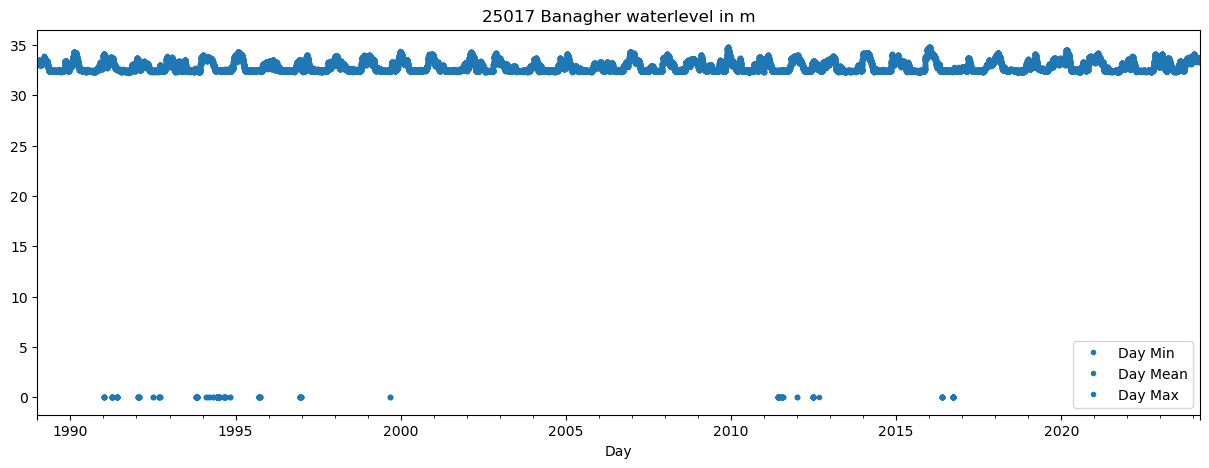

In [39]:
# Select columns except the last one
columns_to_plot = df.iloc[:, :-1]

columns_to_plot.plot(style='.', 
                     figsize=(15,5), 
                     color=colour_pal[0], 
                     title='25017 Banagher waterlevel in m')
plt.show()
# issues here with zeros but I will come to fix this.

In [40]:
#df.index

## Train / Test Split

In [42]:
# later I will change this to full cross validation

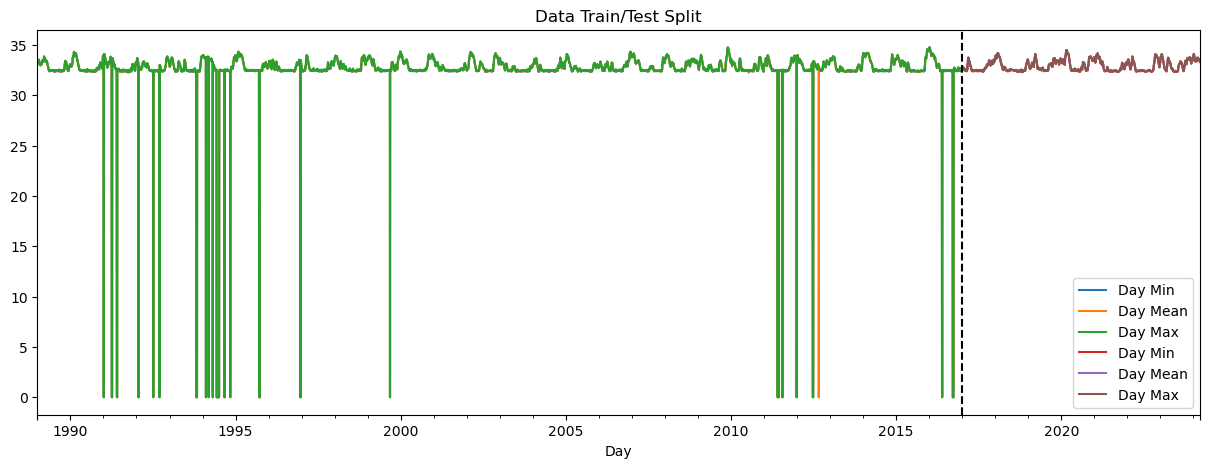

In [57]:
train = df.iloc[:, :-1].loc[df.index < '01-01-2017']
test = df.iloc[:, :-1].loc[df.index >= '01-01-2017']

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')

ax.axvline('01-01-2017', color='black', ls='--')
#ax.legend(['Training Set', 'Test Set'])
plt.show()


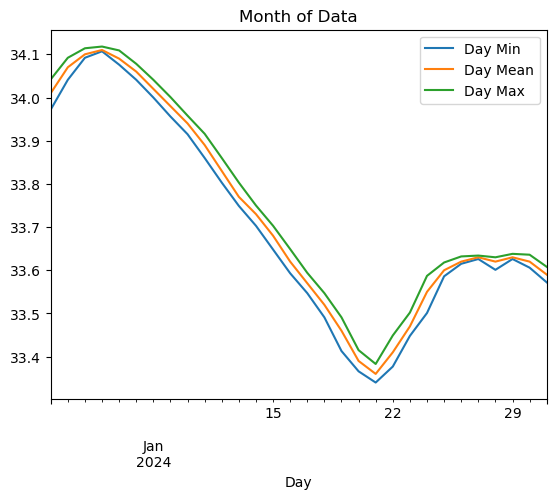

In [64]:
# weekly plot, or monthly
df.iloc[:, :-1].loc[(df.index > '01-01-2024') & (df.index <= '31-01-2024')].plot(title='Month of Data') 
plt.show()